# SG-NEx: starting analyses for Task 2

The [project handout](../reference/handout_project2_RNAModifications.html#task-2-prediction-of-m6a-sites-in-all-sg-nex-direct-rna-seq-data-sets) asks us to predict modifications, compare cell lines, and create an interactive visualization for researchers. This notebook explores the published **full Extra Trees** predictions across the pinned SG-NEx collection. It supplies descriptive comparisons and an interactive starting point, not a completed biological interpretation.

**Run all cells in order.** No training, raw feature download or inference is required. See [setup instructions](../docs/sgnex.md#run-the-analysis-notebook) for the optional environment and RONIN access. Tables and static figures are saved under ignored `reports/sgnex_analysis/`.

- Scores represent predicted site modification, not the fraction of modified reads. There are no ground-truth labels here.
- Read coverage and site availability can differ across samples. A missing site is not an unmodified site.
- We match `(transcript_id, transcript_position)` exactly. These are transcript sites, not deduplicated genomic loci; transcript annotations are not mapped to genes here.
- A minimum of 20 reads and score threshold 0.5 are exploratory choices, not validated cutoffs. We examine sensitivity to both.
- Runs sharing a cell line and replicate ID are averaged before cell-line summaries, so multiple runs do not receive extra replicate weight. This grouping follows the supplied sample metadata.

In [1]:
%matplotlib inline
from pathlib import Path
import json
import hashlib
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import plotly.io as pio
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs/sgnex_samples.json").exists())
DATA = ROOT / "predictions/sgnex/extra_trees"
OUT = ROOT / "reports/sgnex_analysis"
OUT.mkdir(parents=True, exist_ok=True)
MIN_READS = 20
SCORE_THRESHOLD = 0.5
CHUNK_SIZE = 100_000
COVERAGES = sorted(set([1, 5, 10, 20, 50, MIN_READS]))
THRESHOLDS = sorted(set([0.3, 0.5, 0.7, SCORE_THRESHOLD]))
KEYS = ["transcript_id", "transcript_position"]
pio.renderers.default = "plotly_mimetype"
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})
samples = pd.read_csv(DATA / "samples.csv")
manifest = json.loads((DATA / "sample_manifest.json").read_text())
contract = json.loads((DATA / "run_contract.json").read_text())
assert set(samples.sample_id) == {s["sample_id"] for s in manifest["samples"]}
assert not samples.sample_id.duplicated().any()
assert contract["model_manifest"] == json.loads((ROOT / "models/full/extra_trees/model.json").read_text())
for row in samples.itertuples():
    path = DATA / row.predictions
    with path.open("rb") as stream:
        if stream.read(80).startswith(b"version https://git-lfs.github.com/spec/"):
            raise RuntimeError("Prediction is a Git LFS pointer. Run git lfs pull before opening the notebook.")
    complete = json.loads((path.parent / "complete.json").read_text())
    assert all(complete["contract"][k] == v for k, v in contract.items())
    for name, expected in complete["sha256"].items():
        digest = hashlib.sha256()
        with (path.parent / name).open("rb") as stream:
            for block in iter(lambda: stream.read(1024 * 1024), b""):
                digest.update(block)
        assert digest.hexdigest() == expected, f"Checksum mismatch: {path.parent / name}"
display(samples.groupby("cell_line").agg(runs=("sample_id", "size"), replicates=("replicate", "nunique"), predicted_rows=("sites", "sum")))
print(f"Verified {len(samples)} runs and {samples.sites.sum():,} sample-site rows.")
print("Python:", platform.python_version(), "pandas:", pd.__version__, "NumPy:", np.__version__)


,runs,replicates,predicted_rows
cell_line,,,
A549,2,2,2509512
H9,6,3,6782273
HEYA8,5,3,6084243
Hct116,3,2,4293491
HepG2,2,2,3145777
K562,3,3,3156145
MCF7,2,2,2698639


Verified 23 runs and 28,670,080 sample-site rows.
Python: 3.12.8 pandas: 3.0.6 NumPy: 2.5.4


## 1. Coverage, score distributions and threshold sensitivity

We scan one file in chunks instead of loading the entire collection. The first pass calculates exact counts and histograms, and identifies sites with at least `MIN_READS` in **every run within each transcript-ID format cohort**. This common-site restriction supports like-for-like comparisons, but selects consistently observed, well-covered sites and can exclude cell-line-specific biology.

In [2]:
summary_rows, histogram_rows = [], []
common_by_cohort = {}
sample_cohort = {}
indices_by_sample = {}
id_format_rows = []
bins = np.linspace(0, 1, 51)
for row in samples.itertuples():
    counts = {c: 0 for c in COVERAGES}
    sums = {c: 0.0 for c in COVERAGES}
    calls = {(c, t): 0 for c in COVERAGES for t in THRESHOLDS}
    hist = {c: np.zeros(len(bins) - 1, dtype=np.int64) for c in [1, MIN_READS]}
    keys, observed = [], 0
    id_counts = {"ENST_unversioned": 0, "ENST_versioned": 0, "other": 0}
    for chunk in pd.read_csv(DATA / row.predictions, chunksize=CHUNK_SIZE, usecols=KEYS + ["n_reads", "score"]):
        assert chunk.score.between(0, 1).all() and (chunk.n_reads >= 1).all()
        observed += len(chunk)
        plain = chunk.transcript_id.str.fullmatch(r"ENST\d+")
        version = chunk.transcript_id.str.fullmatch(r"ENST\d+\.\d+")
        id_counts["ENST_unversioned"] += int(plain.sum())
        id_counts["ENST_versioned"] += int(version.sum())
        id_counts["other"] += int((~plain & ~version).sum())
        for c in COVERAGES:
            scores = chunk.loc[chunk.n_reads >= c, "score"]
            counts[c] += len(scores)
            sums[c] += scores.sum()
            for t in THRESHOLDS:
                calls[c, t] += int((scores >= t).sum())
        for c in hist:
            hist[c] += np.histogram(chunk.loc[chunk.n_reads >= c, "score"], bins=bins)[0]
        keys.append(chunk.loc[chunk.n_reads >= MIN_READS, KEYS])
    assert observed == row.sites
    index = pd.MultiIndex.from_frame(pd.concat(keys, ignore_index=True))
    assert index.is_unique, f"Duplicate transcript sites in {row.sample_id}"
    versioned = index.get_level_values("transcript_id").str.contains(r"\.\d+$")
    assert versioned.all() or not versioned.any(), "Mixed ID formats require annotation review."
    cohort = "versioned" if versioned.all() else "unversioned"
    sample_cohort[row.sample_id] = cohort
    indices_by_sample[row.sample_id] = index
    id_format_rows.append(dict(sample_id=row.sample_id, cell_line=row.cell_line, **id_counts))
    common_by_cohort[cohort] = index if cohort not in common_by_cohort else common_by_cohort[cohort].intersection(index, sort=False)
    for c in COVERAGES:
        for t in THRESHOLDS:
            summary_rows.append(dict(sample_id=row.sample_id, cell_line=row.cell_line, replicate=row.replicate, run=row.run,
                min_reads=c, threshold=t, sites=counts[c], retained_fraction=counts[c] / observed,
                mean_score=sums[c] / counts[c] if counts[c] else np.nan,
                called_sites=calls[c, t], called_fraction=calls[c, t] / counts[c] if counts[c] else np.nan))
    for c, values in hist.items():
        for i, count in enumerate(values):
            histogram_rows.append(dict(sample_id=row.sample_id, min_reads=c, score_mid=(bins[i] + bins[i+1]) / 2, count=count))
    print(f"{row.sample_id}: {counts[MIN_READS]:,} covered sites; common so far {len(common_by_cohort[cohort]):,} ({cohort})")
    del keys, index
summary = pd.DataFrame(summary_rows)
histograms = pd.DataFrame(histogram_rows)
summary.to_csv(OUT / "coverage_threshold_summary.csv", index=False)
histograms.to_csv(OUT / "score_histograms.csv", index=False)
samples["id_cohort"] = samples.sample_id.map(sample_cohort)
PRIMARY_COHORT = "unversioned"
eligible_lines = samples.groupby("cell_line").id_cohort.apply(lambda x: (x == PRIMARY_COHORT).all())
primary_samples = samples.loc[samples.cell_line.isin(eligible_lines.index[eligible_lines])]
common_sites = None
for sample_id in primary_samples.sample_id:
    index = indices_by_sample[sample_id]
    common_sites = index if common_sites is None else common_sites.intersection(index, sort=False)
del indices_by_sample
id_formats = pd.DataFrame(id_format_rows)
id_formats.to_csv(OUT / "transcript_id_formats.csv", index=False)
display(id_formats)
print("Excluded from matched-site comparisons:", eligible_lines.index[~eligible_lines].tolist())
assert len(common_sites) > 0, "No common sites: review coverage and annotation compatibility."
display(samples.groupby(["id_cohort", "cell_line"]).size().rename("runs"))
print("Common sites by ID cohort:", {k: len(v) for k,v in common_by_cohort.items()})


SGNex_A549_directRNA_replicate5_run1: 66,382 covered sites; common so far 66,382 (unversioned)
SGNex_A549_directRNA_replicate6_run1: 187,021 covered sites; common so far 66,239 (unversioned)
SGNex_H9_directRNA_replicate2_run1: 104,569 covered sites; common so far 49,698 (unversioned)
SGNex_H9_directRNA_replicate2_run2: 51,589 covered sites; common so far 34,676 (unversioned)
SGNex_H9_directRNA_replicate3_run1: 97,837 covered sites; common so far 34,534 (unversioned)
SGNex_H9_directRNA_replicate3_run2: 45,830 covered sites; common so far 29,715 (unversioned)
SGNex_H9_directRNA_replicate4_run1: 147,467 covered sites; common so far 29,715 (unversioned)
SGNex_H9_directRNA_replicate4_run2: 34,202 covered sites; common so far 24,515 (unversioned)
SGNex_HEYA8_directRNA_replicate1_run1: 173,488 covered sites; common so far 24,183 (unversioned)
SGNex_HEYA8_directRNA_replicate1_run2: 40,086 covered sites; common so far 19,240 (unversioned)
SGNex_HEYA8_directRNA_replicate2_run1: 158,731 covered s

,sample_id,cell_line,ENST_unversioned,ENST_versioned,other
0,SGNex_A549_directRNA_replicate5_run1,A549,1008933,0,0
1,SGNex_A549_directRNA_replicate6_run1,A549,1500579,0,0
2,SGNex_H9_directRNA_replicate2_run1,H9,1242801,0,3887
3,SGNex_H9_directRNA_replicate2_run2,H9,1019529,0,3539
4,SGNex_H9_directRNA_replicate3_run1,H9,1224088,0,3364
5,SGNex_H9_directRNA_replicate3_run2,H9,971752,0,3291
6,SGNex_H9_directRNA_replicate4_run1,H9,1419091,0,3962
7,SGNex_H9_directRNA_replicate4_run2,H9,884082,0,2887
8,SGNex_HEYA8_directRNA_replicate1_run1,HEYA8,1337788,0,2341
9,SGNex_HEYA8_directRNA_replicate1_run2,HEYA8,832553,0,1750


Excluded from matched-site comparisons: ['MCF7']


id_cohort    cell_line
unversioned  A549         2
             H9           6
             HEYA8        5
             Hct116       3
             HepG2        2
             K562         3
             MCF7         1
versioned    MCF7         1
Name: runs, dtype: int64

Common sites by ID cohort: {'unversioned': 14992, 'versioned': 109315}


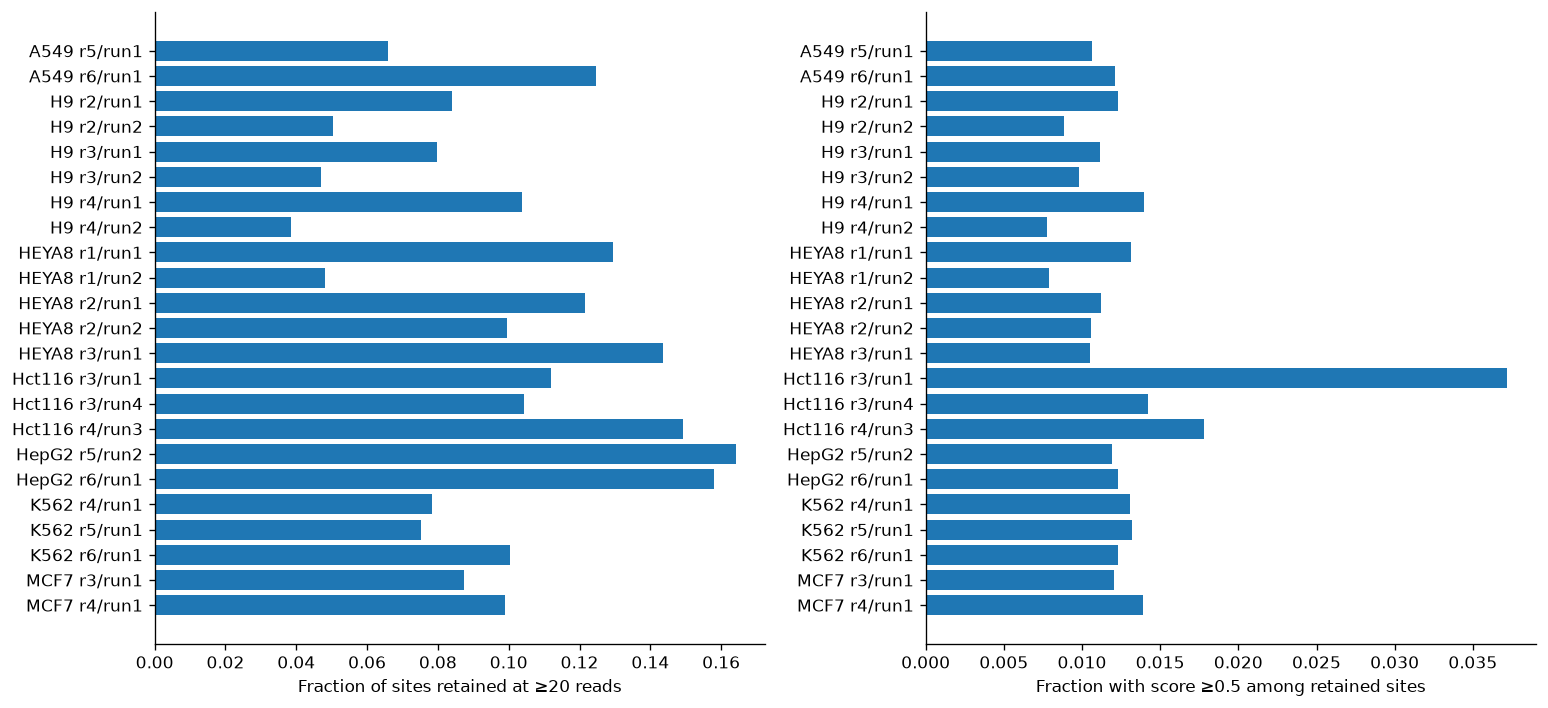

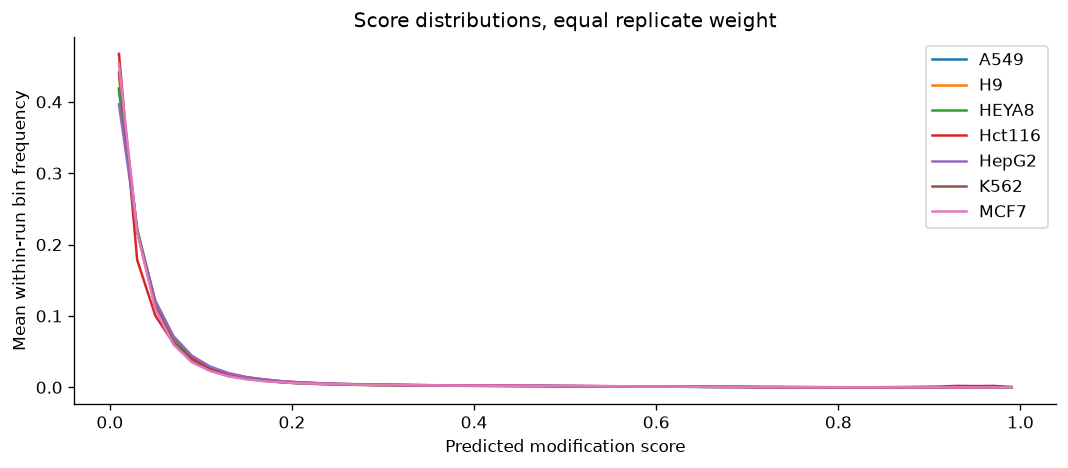

threshold               0.3     0.5     0.7
cell_line min_reads                        
A549      1          0.0167  0.0020  0.0001
          5          0.0302  0.0056  0.0004
          10         0.0337  0.0083  0.0007
          20         0.0357  0.0114  0.0013
          50         0.0379  0.0144  0.0029
H9        1          0.0162  0.0017  0.0001
          5          0.0302  0.0053  0.0003
          10         0.0320  0.0081  0.0006
          20         0.0319  0.0106  0.0012
          50         0.0338  0.0134  0.0027
HEYA8     1          0.0172  0.0022  0.0001
          5          0.0291  0.0056  0.0003
          10         0.0314  0.0081  0.0006
          20         0.0324  0.0107  0.0010
          50         0.0333  0.0127  0.0021
Hct116    1          0.0236  0.0041  0.0012
          5          0.0405  0.0102  0.0031
          10         0.0447  0.0151  0.0054
          20         0.0474  0.0217  0.0101
          50         0.0489  0.0268  0.0140
HepG2     1          0.0198  0.0030  0.0002
          5          0.0320  0.0064  0.0004
          10         0.0357  0.0090  0.0006
          20         0.0384  0.0121  0.0011
          50         0.0404  0.0151  0.0021
K562      1          0.0165  0.0020  0.0001
          5          0.0303  0.0059  0.0004
          10         0.0334  0.0090  0.0008
          20         0.0356  0.0129  0.0016
          50         0.0380  0.0170  0.0035
MCF7      1          0.0170  0.0022  0.0001
          5          0.0309  0.0060  0.0004
          10         0.0347  0.0092  0.0008
          20         0.0377  0.0130  0.0015
          50         0.0402  0.0175  0.0034

In [3]:
baseline = summary.query("min_reads == @MIN_READS and threshold == @SCORE_THRESHOLD")
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
labels = samples.apply(lambda r: f"{r.cell_line} r{r.replicate}/run{r.run}", axis=1)
ordered = baseline.set_index("sample_id").loc[samples.sample_id]
axes[0].barh(labels, ordered.retained_fraction)
axes[0].set_xlabel(f"Fraction of sites retained at ≥{MIN_READS} reads")
axes[1].barh(labels, ordered.called_fraction)
axes[1].set_xlabel(f"Fraction with score ≥{SCORE_THRESHOLD} among retained sites")
for ax in axes:
    ax.invert_yaxis()
fig.tight_layout()
fig.savefig(OUT / "coverage_and_calls.png", bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(9, 4))
for cell_line, group in samples.groupby("cell_line"):
    h = histograms.query("min_reads == @MIN_READS").merge(group[["sample_id", "replicate"]], on="sample_id")
    h["frequency"] = h["count"] / h.groupby("sample_id")["count"].transform("sum")
    curve = h.groupby(["replicate", "score_mid"]).frequency.mean().groupby("score_mid").mean()
    ax.plot(curve.index, curve.values, label=cell_line)
ax.set(xlabel="Predicted modification score", ylabel="Mean within-run bin frequency", title="Score distributions, equal replicate weight")
ax.legend(); fig.tight_layout(); fig.savefig(OUT / "score_distributions.png", bbox_inches="tight"); plt.show()

sensitivity = summary.groupby(["cell_line", "replicate", "min_reads", "threshold"]).called_fraction.mean().groupby(["cell_line", "min_reads", "threshold"]).mean().unstack("threshold")
display(sensitivity.round(4))


**Discussion prompt:** Do cell-line rankings persist across coverage and score thresholds? These first summaries use each sample's available sites, so differences can reflect which transcripts/sites were observed, not only differences at a fixed set of sites. A high score fraction is not a measured biological modification rate.

## 2. Compare the same sites across runs and cell lines

**Annotation caveat found in the supplied predictions:** MCF7 replicate 3 uses versioned transcript IDs; replicate 4 contains unversioned IDs and other identifiers. The other cell lines use unversioned IDs in the covered-site cohort. Exact matching across all runs gives no common sites. We keep MCF7 in the distribution summaries and exclude both its runs from matched-site comparisons until annotation compatibility is resolved. The primary matched-site analysis includes cell lines whose runs all belong to the unversioned cohort, so no cell line is represented by only one of its replicates. We do not strip suffixes: compatibility of transcript sequences and positions has not been established. Even identical unversioned IDs do not prove the same annotation release was used.

The second pass retains only the common-site cohort within each ID format. Each run contributes one score per site. We average runs within the same replicate, then average replicates within each cell line. The coverage filter uses no prediction scores.

Spearman correlations describe agreement in score ranking. They do not establish accuracy, and shared sequence/coverage effects may contribute to agreement.

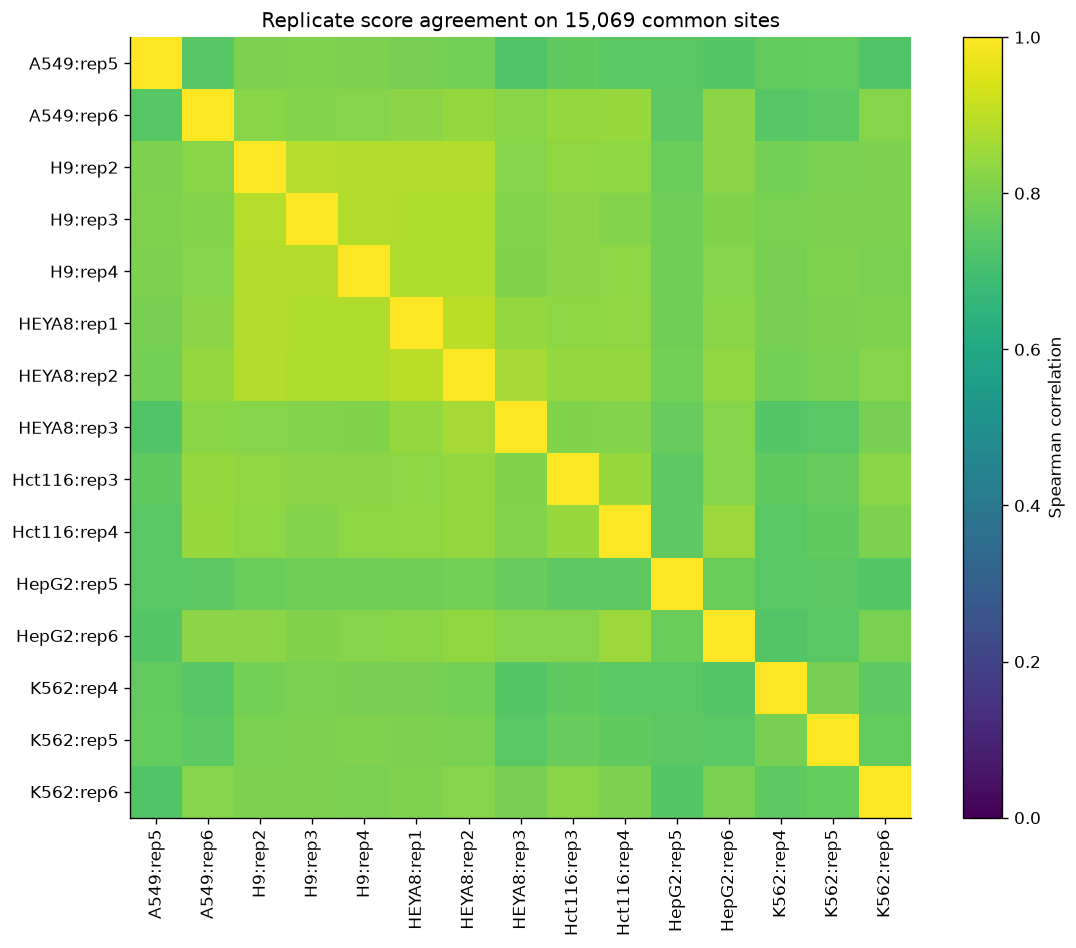

,count,median,min,max
same_cell_line,,,,
False,93,0.803426,0.727177,0.885002
True,12,0.845478,0.742150,0.898216


,common_mean_score,common_fraction_above_threshold,available_site_mean_call_fraction
A549,0.0544,0.0117,0.0114
H9,0.0513,0.0118,0.0106
HEYA8,0.0543,0.0122,0.0107
Hct116,0.0629,0.0250,0.0217
HepG2,0.0589,0.0119,0.0121
K562,0.0516,0.0137,0.0129


In [4]:
def load_common_scores(group, index):
    result = pd.DataFrame(index=index)
    for row in group.itertuples():
        values = pd.Series(index=index, dtype="float64")
        for chunk in pd.read_csv(DATA / row.predictions, chunksize=CHUNK_SIZE, usecols=KEYS + ["score"]):
            selected = chunk.set_index(KEYS)["score"]
            shared = selected.index.intersection(index, sort=False)
            values.loc[shared] = selected.loc[shared]
        assert values.notna().all()
        result[row.sample_id] = values
    return result

matrix = load_common_scores(primary_samples, common_sites)
replicate_scores = pd.DataFrame(index=common_sites)
for (cell_line, replicate), group in primary_samples.groupby(["cell_line", "replicate"]):
    replicate_scores[f"{cell_line}:rep{replicate}"] = matrix[group.sample_id].mean(axis=1)
cell_scores = pd.DataFrame({cell_line: replicate_scores.filter(like=f"{cell_line}:").mean(axis=1)
                            for cell_line in sorted(primary_samples.cell_line.unique())})
cell_scores.to_csv(OUT / "common_site_cell_line_scores.csv")
rep_corr = replicate_scores.corr(method="spearman")
cell_corr = cell_scores.corr(method="spearman")
matrix.corr(method="spearman").to_csv(OUT / "run_spearman.csv")
rep_corr.to_csv(OUT / "replicate_spearman.csv")
cell_corr.to_csv(OUT / "cell_line_spearman.csv")
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(rep_corr, vmin=0, vmax=1, cmap="viridis")
ax.set_xticks(range(len(rep_corr)), rep_corr.columns, rotation=90)
ax.set_yticks(range(len(rep_corr)), rep_corr.index)
ax.set_title(f"Replicate score agreement on {len(common_sites):,} common sites")
fig.colorbar(im, ax=ax, label="Spearman correlation")
fig.tight_layout(); fig.savefig(OUT / "replicate_agreement.png", bbox_inches="tight"); plt.show()

pairs = []
for i, a in enumerate(rep_corr.columns):
    for b in rep_corr.columns[i+1:]:
        pairs.append({"replicate_a": a, "replicate_b": b, "same_cell_line": a.split(":")[0] == b.split(":")[0], "spearman": rep_corr.loc[a,b]})
pairs = pd.DataFrame(pairs)
display(pairs.groupby("same_cell_line").spearman.agg(["count", "median", "min", "max"]))
comparison = pd.DataFrame({"common_mean_score": cell_scores.mean(),
    "common_fraction_above_threshold": (cell_scores >= SCORE_THRESHOLD).mean()})
available = baseline.groupby(["cell_line", "replicate"]).called_fraction.mean().groupby("cell_line").mean()
comparison["available_site_mean_call_fraction"] = available
comparison.to_csv(OUT / "cell_line_comparison.csv")
display(comparison.round(4))


The common-site fraction thresholds the **cell-line mean score**; the available-site fraction averages **per-run thresholded fractions**. They have different denominators and aggregation rules, so their numerical difference is not a pure coverage effect. Within-cell and between-cell correlation pairs also share replicates; treat their summaries descriptively, not as independent observations in a significance test.

## 3. Candidate differences for follow-up

Rank common transcript sites by the difference between their highest and lowest cell-line mean score. Also check whether the replicate score ranges overlap for those two cell lines. This helps identify candidates for discussion, not statistically significant differential modification. Selection and description use the same data; there is no independent validation or multiple-testing correction.

A candidate needs transcript/genome annotation, coverage review and biological evidence before a mechanistic interpretation. Missing sites and different transcript isoforms are not collapsed into gene-level claims.

In [5]:
candidates = cell_scores.copy()
candidates["highest_cell_line"] = cell_scores.idxmax(axis=1)
candidates["lowest_cell_line"] = cell_scores.idxmin(axis=1)
candidates["score_range"] = cell_scores.max(axis=1) - cell_scores.min(axis=1)
candidates = candidates.sort_values("score_range", ascending=False).head(100).copy()
gaps = []
for key, row in candidates.iterrows():
    high = replicate_scores.loc[key, replicate_scores.columns.str.startswith(row.highest_cell_line + ":")]
    low = replicate_scores.loc[key, replicate_scores.columns.str.startswith(row.lowest_cell_line + ":")]
    gaps.append(high.min() - low.max())
candidates["replicate_separation_gap"] = gaps
candidates.to_csv(OUT / "candidate_sites.csv")
display(candidates.head(15).round(3))


,,A549,H9,HEYA8,Hct116,HepG2,K562,highest_cell_line,lowest_cell_line,score_range,replicate_separation_gap
transcript_id,transcript_position,,,,,,,,,,
ENST00000331789,652,0.498,0.663,0.703,0.881,0.325,0.766,Hct116,HepG2,0.556,0.530
ENST00000269349,212,0.392,0.361,0.579,0.811,0.268,0.527,Hct116,HepG2,0.543,0.487
ENST00000215570,772,0.113,0.583,0.258,0.644,0.367,0.492,Hct116,A549,0.531,0.423
ENST00000339647,1819,0.367,0.270,0.202,0.592,0.088,0.551,Hct116,HepG2,0.504,0.320
ENST00000462494,985,0.355,0.489,0.608,0.774,0.270,0.633,Hct116,HepG2,0.504,0.390
ENST00000425660,585,0.402,0.437,0.599,0.786,0.297,0.602,Hct116,HepG2,0.489,0.430
ENST00000324460,2169,0.510,0.442,0.299,0.744,0.638,0.261,Hct116,K562,0.483,0.383
ENST00000359995,503,0.378,0.372,0.459,0.653,0.197,0.228,Hct116,HepG2,0.456,0.360
ENST00000305218,1923,0.487,0.493,0.504,0.743,0.522,0.296,Hct116,K562,0.448,0.313


## 4. Interactive starting point for researchers

Hover over the cell-line heatmap to inspect correlations. In the site explorer, choose a candidate transcript site to see individual replicate scores and cell-line means. This is a local interactive notebook prototype for Task 2; the exported HTML files can also be opened without a notebook server. The explorer contains the top candidates, not every predicted site.

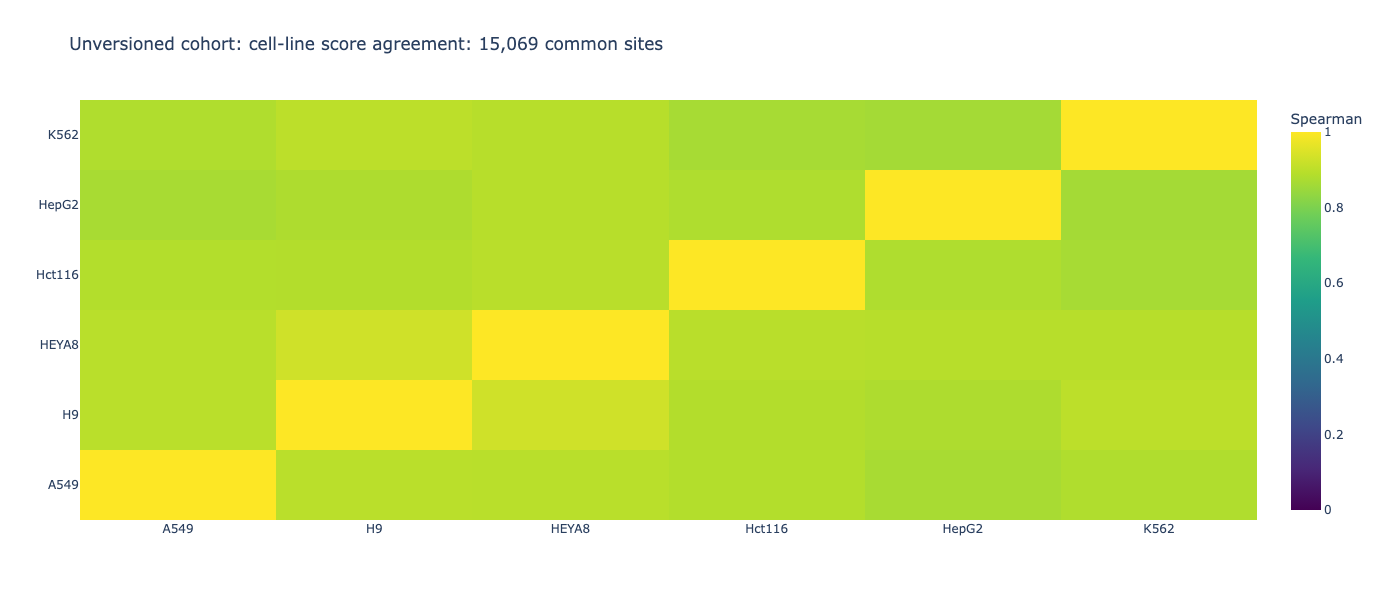

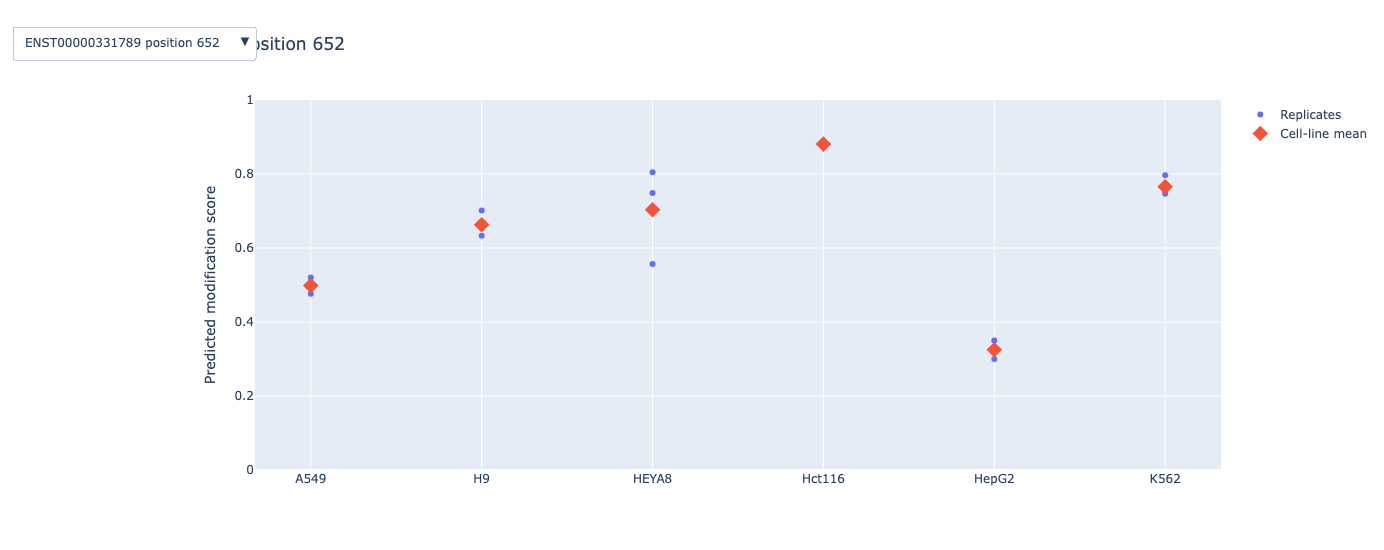

In [6]:
fig = go.Figure(go.Heatmap(z=cell_corr.to_numpy(), x=cell_corr.columns, y=cell_corr.index,
                          zmin=0, zmax=1, colorscale="Viridis", colorbar_title="Spearman"))
fig.update_layout(title=f"Unversioned cohort: cell-line score agreement: {len(common_sites):,} common sites", width=750, height=600)
fig.write_html(OUT / "cell_line_heatmap.html", include_plotlyjs=True)
fig.show()

fig = go.Figure()
buttons = []
rep_lines = [name.split(":")[0] for name in replicate_scores.columns]
for i, (key, row) in enumerate(candidates.head(30).iterrows()):
    title = f"{key[0]} position {key[1]}"
    fig.add_trace(go.Scatter(x=rep_lines, y=replicate_scores.loc[key].values, mode="markers",
        text=replicate_scores.columns, name="Replicates", visible=i==0,
        hovertemplate="%{text}<br>Score %{y:.3f}<extra></extra>"))
    fig.add_trace(go.Scatter(x=cell_scores.columns, y=cell_scores.loc[key].values, mode="markers",
        marker=dict(symbol="diamond", size=12), name="Cell-line mean", visible=i==0))
    visibility = [False] * (2 * min(30, len(candidates)))
    visibility[2*i:2*i+2] = [True, True]
    buttons.append(dict(label=title, method="update", args=[{"visible": visibility}, {"title": title}]))
fig.update_layout(title=buttons[0]["label"], yaxis=dict(title="Predicted modification score", range=[0,1]),
    updatemenus=[dict(buttons=buttons, direction="down", x=0, y=1.2)], height=550)
fig.write_html(OUT / "candidate_explorer.html", include_plotlyjs=True)
fig.show()


## 5. Data-driven starting observations

The following cell generates observations from this run, so they update if you change the exploratory filters. Use them as discussion leads rather than biological conclusions.

In [7]:
within = pairs.loc[pairs.same_cell_line, "spearman"].median()
between = pairs.loc[~pairs.same_cell_line, "spearman"].median()
coverage_low = baseline.loc[baseline.retained_fraction.idxmin()]
coverage_high = baseline.loc[baseline.retained_fraction.idxmax()]
ranked = comparison.common_mean_score.sort_values(ascending=False)
run_spreads = baseline.groupby(["cell_line", "replicate"]).called_fraction.agg(["size", "min", "max"])
run_spreads = run_spreads.loc[run_spreads["size"] > 1].copy()
run_spreads["spread"] = run_spreads["max"] - run_spreads["min"]
largest = run_spreads.sort_values("spread", ascending=False).iloc[0]
largest_key = run_spreads["spread"].idxmax()
text = f"""- **Coverage matters:** the fraction of sites retained at ≥{MIN_READS} reads ranges from {coverage_low.retained_fraction:.1%} ({coverage_low.sample_id}) to {coverage_high.retained_fraction:.1%} ({coverage_high.sample_id}). Compare this with the initial score distributions before attributing differences to cell-line biology.
- **Matched comparison:** {len(common_sites):,} transcript sites pass coverage in every run of the six eligible cell lines. MCF7 is excluded from matched-site comparisons because transcript-coordinate compatibility is unresolved. Conclusions from this cohort apply to these consistently covered sites, not every predicted site.
- **Replicate agreement:** median within-cell-line Spearman correlation is {within:.3f}; between-cell-line median is {between:.3f}. Consider technical reproducibility alongside cell-line differences; neither correlation is an accuracy estimate.
- **Cell-line scores:** on this cohort, {ranked.index[0]} has the highest mean score ({ranked.iloc[0]:.3f}) and {ranked.index[-1]} the lowest ({ranked.iloc[-1]:.3f}). Check threshold sensitivity and replicate variation before interpreting this ranking.
- **Run variation:** {largest_key[0]} replicate {largest_key[1]} has the largest within-replicate spread in available-site call fractions: {largest["min"]:.2%} to {largest["max"]:.2%}. Check coverage, site composition and processing differences before interpreting elevated scores biologically.
- **Next steps:** inspect candidate replicate ranges, add compatible transcript/genome annotations, and decide on a coverage/replicate support rule before making biological claims. A broader explorer could add transcript search and pairwise site comparisons, which retain sites excluded by the all-run intersection.
"""
display(Markdown(text))
(OUT / "starting_observations.md").write_text(text)
settings = dict(min_reads=MIN_READS, score_threshold=SCORE_THRESHOLD, coverage_grid=COVERAGES,
    threshold_grid=THRESHOLDS, common_sites=len(common_sites), samples=len(samples),
    model_sha256=contract["model_manifest"]["sha256"], manifest_sha256=contract["manifest_sha256"])
(OUT / "analysis_settings.json").write_text(json.dumps(settings, indent=2))
print("Saved analysis outputs to", OUT)


- **Coverage matters:** the fraction of sites retained at ≥20 reads ranges from 3.9% (SGNex_H9_directRNA_replicate4_run2) to 16.4% (SGNex_HepG2_directRNA_replicate5_run2). Compare this with the initial score distributions before attributing differences to cell-line biology.
- **Matched comparison:** 15,069 transcript sites pass coverage in every run of the six eligible cell lines. MCF7 is excluded from matched-site comparisons because transcript-coordinate compatibility is unresolved. Conclusions from this cohort apply to these consistently covered sites, not every predicted site.
- **Replicate agreement:** median within-cell-line Spearman correlation is 0.845; between-cell-line median is 0.803. Consider technical reproducibility alongside cell-line differences; neither correlation is an accuracy estimate.
- **Cell-line scores:** on this cohort, Hct116 has the highest mean score (0.063) and H9 the lowest (0.051). Check threshold sensitivity and replicate variation before interpreting this ranking.
- **Run variation:** Hct116 replicate 3 has the largest within-replicate spread in available-site call fractions: 1.42% to 3.72%. Check coverage, site composition and processing differences before interpreting elevated scores biologically.
- **Next steps:** inspect candidate replicate ranges, add compatible transcript/genome annotations, and decide on a coverage/replicate support rule before making biological claims. A broader explorer could add transcript search and pairwise site comparisons, which retain sites excluded by the all-run intersection.


Saved analysis outputs to /Users/ncduy/Git/DSA4262-Big-Study-Group/reports/sgnex_analysis
